<a href="https://colab.research.google.com/github/22495521/99-multiplication-table/blob/main/10_01_DCGAN_AnimeFaces_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 實作DCGAN演算法，產生動漫人臉 (Colab 版)

訓練資料為 `animefaces` 資料夾內的 64x64 動漫人臉圖片。

**使用前請先把資料壓縮成 `animefaces.zip` 上傳到 Google Drive**，
預設位置為 `MyDrive/colab_file/animefaces.zip`(可在下方 `DRIVE_DIR` 修改)。

記得先切換到 GPU：`執行階段` → `變更執行階段類型` → `T4 GPU`。

## 檢查 GPU 環境

In [1]:
!nvidia-smi -L

import torch
print("torch", torch.__version__, "| CUDA 可用：", torch.cuda.is_available())

GPU 0: NVIDIA RTX PRO 6000 Blackwell Server Edition (UUID: GPU-33477324-ccff-84ff-bb42-6a942856f6af)
torch 2.11.0+cu130 | CUDA 可用： True


## 掛載 Google Drive 並解壓訓練資料

In [2]:
import shutil
import zipfile
from pathlib import Path

DATA_SOURCE = "drive"  # "drive" 或 "upload"
DRIVE_DIR = Path("/content/drive/MyDrive/colab_file")
ZIP_NAME = "animefaces.zip"

CONTENT = Path("/content")
DATA_DIR = CONTENT / "animefaces"

if DATA_SOURCE == "drive":
    from google.colab import drive

    drive.mount("/content/drive")
    zip_path = DRIVE_DIR / ZIP_NAME
    assert zip_path.exists(), f"找不到 {zip_path}，請先把 zip 上傳到 Drive 的這個位置"
    OUTPUT_DIR = DRIVE_DIR / "dcgan_outputs"  # 權重與樣張存回 Drive
else:
    from google.colab import files

    uploaded = files.upload()  # 跳出選檔視窗，選 animefaces.zip
    zip_path = CONTENT / next(iter(uploaded))
    OUTPUT_DIR = CONTENT / "dcgan_outputs"  # 斷線會消失，記得自己下載權重

if not DATA_DIR.exists():
    local_zip = CONTENT / ZIP_NAME
    if zip_path != local_zip:
        shutil.copy(zip_path, local_zip)  # 先複製到本機磁碟，解壓比直接讀 Drive 快
    with zipfile.ZipFile(local_zip) as zf:
        zf.extractall(CONTENT)

# 防呆：如果 zip 裡沒有包一層 animefaces/，圖片會直接散在 /content
if not DATA_DIR.exists():
    loose = list(CONTENT.glob("*.jpg"))
    assert loose, "解壓後找不到任何 jpg，請檢查 zip 結構"
    DATA_DIR.mkdir()
    for f in loose:
        shutil.move(str(f), DATA_DIR / f.name)

IMG_FILES = sorted(DATA_DIR.glob("*.jpg"))
assert IMG_FILES, f"{DATA_DIR} 內沒有 jpg 檔，請檢查 zip 結構"

OUT_IMG = OUTPUT_DIR / "gan_output"
OUT_W = OUTPUT_DIR / "gan_weights"
OUT_IMG.mkdir(parents=True, exist_ok=True)
OUT_W.mkdir(parents=True, exist_ok=True)

print("資料集位置：", DATA_DIR, f"({len(IMG_FILES)} 張)")
print("輸出位置：", OUTPUT_DIR)

Mounted at /content/drive
資料集位置： /content/animefaces (13987 張)
輸出位置： /content/drive/MyDrive/colab_file/dcgan_outputs


## 載入套件

In [3]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision import utils as vutils
from PIL import Image

## 設定參數

In [4]:
IMAGE_SIZE = 64  # 圖片尺寸
NC = 3           # 圖片通道數(RGB)
BATCH_SIZE = 128 # 批量(Colab GPU 記憶體夠，可比本機大)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 載入動漫人臉訓練資料
animefaces 資料夾內的圖片是平鋪的(沒有分類子資料夾)，所以自訂 Dataset 直接讀取。

In [5]:
class AnimeFaceDataset(Dataset):
    def __init__(self, files, transform=None):
        self.files = files
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert('RGB')
        if self.transform is not None:
            img = self.transform(img)
        # 回傳 (影像, 標籤)，GAN 不需標籤，固定給 0
        return img, 0


# 轉換
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

dataset = AnimeFaceDataset(IMG_FILES, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=True, drop_last=True)

# 訓練資料的數量與維度
print(f'圖片張數: {len(dataset)}')
print(f'單張維度: {dataset[0][0].shape}')
print(f'批次數量: {len(dataloader)}')

圖片張數: 13987
單張維度: torch.Size([3, 64, 64])
批次數量: 109


## 定義神經網路參數

In [6]:
nz = 100  # 生成神經網路雜訊維度
ngf = 64  # 生成神經網路濾波器個數
ndf = 64  # 判別神經網路濾波器個數

## 神經網路權重初始值

In [7]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.02) # 卷積層權重初始值
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(1.0, 0.02) # Batch Normalization 層權重初始值
        m.bias.data.fill_(0)

## 定義生成神經網路
輸出為 64x64 三通道彩色圖片。

In [8]:
class Generator(nn.Module):
    def __init__(self, nc=NC, nz=100, ngf=64):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # input is Z, going into a convolution
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. (ngf) x 32 x 32
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
            # state size. (nc) x 64 x 64
        )

    def forward(self, input):
        output = self.main(input)
        return output

netG = Generator().to(device)
netG.apply(weights_init)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)

## 定義判別神經網路
輸入為 64x64 三通道，最後一層把特徵圖降到 1x1。

In [9]:
class Discriminator(nn.Module):
    def __init__(self, nc=NC, ndf=64):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # input is (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 32 x 32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*8) x 4 x 4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        output = self.main(input)
        return output.view(-1, 1).squeeze(1)

netD = Discriminator().to(device)
netD.apply(weights_init)

Discriminator(
  (main): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)

## 設定損失函數、優化器(optimizer)

In [10]:
# 設定損失函數
criterion = nn.BCELoss()

# 設定優化器(optimizer)
optimizerD = torch.optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

## 進行模型訓練
樣張與權重都會存到 Drive 的 `dcgan_outputs/`，Colab 斷線後重跑也不會遺失。

In [11]:
fixed_noise = torch.randn(64, nz, 1, 1, device=device)
real_label = 1.0
fake_label = 0.0
niter = 25
# 模型訓練
for epoch in range(niter):
    for i, data in enumerate(dataloader, 0):
        ########################################################
        # (1) 判別神經網路: maximize log(D(x)) + log(1 - D(G(z)))
        #######################################################
        # 訓練真實資料
        netD.zero_grad()
        real_cpu = data[0].to(device)
        batch_size = real_cpu.size(0)
        label = torch.full((batch_size,), real_label, dtype=torch.float, device=device)

        output = netD(real_cpu)
        errD_real = criterion(output, label)
        errD_real.backward()
        D_x = output.mean().item()

        # 訓練假資料
        noise = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label.fill_(fake_label)
        output = netD(fake.detach())
        errD_fake = criterion(output, label)
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        errD = errD_real + errD_fake
        optimizerD.step()

        ########################################################
        # (2) 生成神經網路: maximize log(D(G(z)))
        #######################################################
        netG.zero_grad()
        label.fill_(real_label)
        output = netD(fake)
        errG = criterion(output, label)
        errG.backward()
        D_G_z2 = output.mean().item()
        optimizerG.step()
        if i % 50 == 0:
            print('[%d/%d][%d/%d] Loss_D: %.4f Loss_G: %.4f D(x): %.4f D(G(z)): %.4f / %.4f'
                   % (epoch+1, niter, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))
    # 每個 epoch 結束存一次樣張與權重
    vutils.save_image(real_cpu, str(OUT_IMG / 'real_samples.png'), normalize=True)
    with torch.no_grad():
        fake = netG(fixed_noise)
    vutils.save_image(fake, str(OUT_IMG / ('fake_samples_epoch_%03d.png' % epoch)),
                      normalize=True)
    torch.save(netG.state_dict(), str(OUT_W / ('netG_epoch_%d.pth' % epoch)))
    torch.save(netD.state_dict(), str(OUT_W / ('netD_epoch_%d.pth' % epoch)))

[1/25][0/109] Loss_D: 2.1798 Loss_G: 1.9434 D(x): 0.2605 D(G(z)): 0.3165 / 0.1786
[1/25][50/109] Loss_D: 0.5876 Loss_G: 6.7299 D(x): 0.7715 D(G(z)): 0.0021 / 0.0043
[1/25][100/109] Loss_D: 1.9228 Loss_G: 15.5626 D(x): 0.9580 D(G(z)): 0.7538 / 0.0000
[2/25][0/109] Loss_D: 0.6306 Loss_G: 11.2857 D(x): 0.7004 D(G(z)): 0.0016 / 0.0001
[2/25][50/109] Loss_D: 0.4086 Loss_G: 6.0898 D(x): 0.7976 D(G(z)): 0.0195 / 0.0038
[2/25][100/109] Loss_D: 0.4016 Loss_G: 5.0886 D(x): 0.7831 D(G(z)): 0.0385 / 0.0163
[3/25][0/109] Loss_D: 0.4796 Loss_G: 2.6777 D(x): 0.7760 D(G(z)): 0.0798 / 0.1354
[3/25][50/109] Loss_D: 0.7880 Loss_G: 5.1132 D(x): 0.7576 D(G(z)): 0.2599 / 0.0112
[3/25][100/109] Loss_D: 0.5454 Loss_G: 4.5219 D(x): 0.8246 D(G(z)): 0.2344 / 0.0208
[4/25][0/109] Loss_D: 0.5708 Loss_G: 5.9593 D(x): 0.8609 D(G(z)): 0.2635 / 0.0045
[4/25][50/109] Loss_D: 0.1942 Loss_G: 5.4086 D(x): 0.9051 D(G(z)): 0.0287 / 0.0084
[4/25][100/109] Loss_D: 0.7562 Loss_G: 2.0714 D(x): 0.6237 D(G(z)): 0.0241 / 0.1789
[5

## 新資料預測

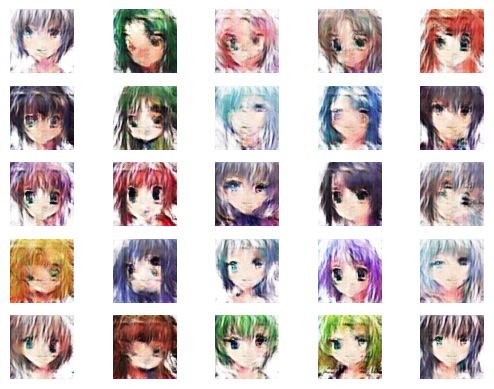

In [12]:
import matplotlib.pyplot as plt
import numpy as np

batch_size = 25
latent_size = 100

noise = torch.randn(batch_size, latent_size, 1, 1).to(device)
with torch.no_grad():
    fake_images = netG(noise)
# (N, 3, 64, 64) -> (N, 64, 64, 3)，並把 [-1, 1] 還原為 [0, 1]
fake_images_np = fake_images.cpu().numpy().transpose(0, 2, 3, 1)
fake_images_np = np.clip(fake_images_np * 0.5 + 0.5, 0, 1)
R, C = 5, 5
for i in range(batch_size):
    plt.subplot(R, C, i + 1)
    plt.axis('off')
    plt.imshow(fake_images_np[i])
plt.show()

## 顯示 GIF 檔

In [13]:
import imageio.v2 as imageio

# 產生 GIF 檔
anim_file = OUT_IMG / 'dcgan.gif'
filenames = sorted(OUT_IMG.glob('fake_samples_epoch_*.png'))
with imageio.get_writer(str(anim_file), mode='I', duration=0.3) as writer:
    for filename in filenames:
        writer.append_data(imageio.imread(str(filename)))
print('GIF 已存到：', anim_file)

GIF 已存到： /content/drive/MyDrive/colab_file/dcgan_outputs/gan_output/dcgan.gif


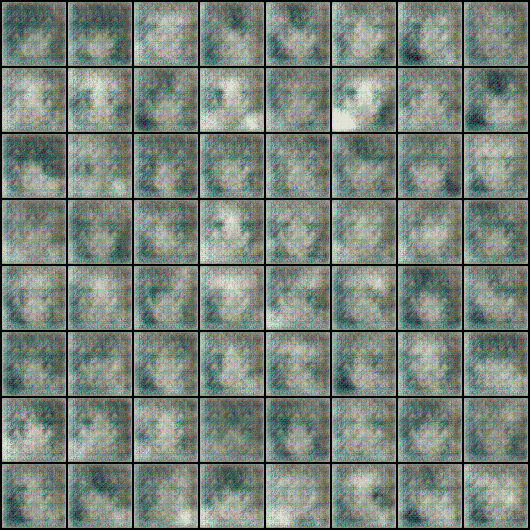

In [14]:
from IPython.display import Image as IPyImage

IPyImage(filename=str(anim_file))